<a href="https://colab.research.google.com/github/d03antony-ai/labo-momentum/blob/main/notebook/riccati_lq_montecarlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

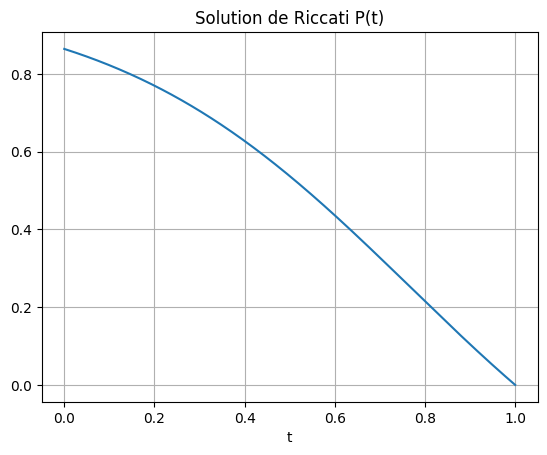

Coût optimal Monte-Carlo : 0.6782 ± 0.0140
Valeur théorique V(0,x0) : 0.6812
Coût sans contrôle      : 1.2134


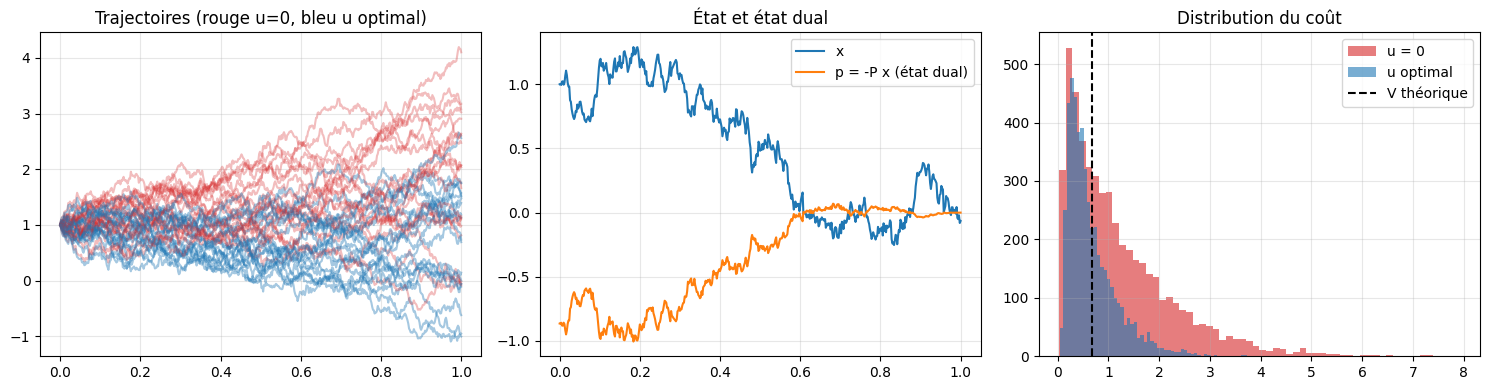

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== 1. Paramètres du problème (cas scalaire) =====
A, C, M, N = 0.5, 1.0, 1.0, 0.5
T, x0 = 1.0, 1.0
n_pas, n_sim = 500, 5000
dt = T / n_pas
t = np.linspace(0, T, n_pas + 1)
rng = np.random.default_rng(0)

# ===== 2. Équation de Riccati, résolue à rebours depuis P(T) = 0 =====
# dP/dt = -(2 A P - (C²/N) P² + M²)
riccati = lambda s, P: -(2*A*P - (C**2/N)*P**2 + M**2)
sol = solve_ivp(riccati, [T, 0], [0.0], t_eval=t[::-1], rtol=1e-10, atol=1e-12)
P = sol.y[0][::-1]
K = C * P / N  # gain du contrôle optimal : u = -K x

plt.plot(t, P); plt.title("Solution de Riccati P(t)"); plt.xlabel("t"); plt.grid(); plt.show()

# ===== 3. Simulation (Euler-Maruyama, même bruit pour les deux stratégies) =====
dW = rng.normal(0, np.sqrt(dt), (n_sim, n_pas))

def simuler(controle):
    x = np.full(n_sim, x0); X = [x.copy()]; cout = np.zeros(n_sim)
    for k in range(n_pas):
        u = -K[k] * x if controle else 0.0
        cout += 0.5 * (M**2 * x**2 + N * u**2) * dt
        x = x + (A*x + C*u) * dt + dW[:, k]
        X.append(x.copy())
    return np.array(X).T, cout

X_opt, J_opt = simuler(True)
X_0, J_0 = simuler(False)

# Valeur théorique : V(0,x0) = ½ P(0) x0² + ½ ∫ P dt
V_theo = 0.5*P[0]*x0**2 + 0.5*np.trapezoid(P, t)
print(f"Coût optimal Monte-Carlo : {J_opt.mean():.4f} ± {1.96*J_opt.std()/np.sqrt(n_sim):.4f}")
print(f"Valeur théorique V(0,x0) : {V_theo:.4f}")
print(f"Coût sans contrôle      : {J_0.mean():.4f}")

# ===== 4. Graphiques =====
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(20):
    ax[0].plot(t, X_0[i], color="tab:red", alpha=.3)
    ax[0].plot(t, X_opt[i], color="tab:blue", alpha=.4)
ax[0].set_title("Trajectoires (rouge u=0, bleu u optimal)")

ax[1].plot(t, X_opt[0], label="x")
ax[1].plot(t, -P * X_opt[0], label="p = -P x (état dual)")
ax[1].set_title("État et état dual"); ax[1].legend()

ax[2].hist(J_0, bins=60, alpha=.6, label="u = 0", color="tab:red")
ax[2].hist(J_opt, bins=60, alpha=.6, label="u optimal", color="tab:blue")
ax[2].axvline(V_theo, color="k", ls="--", label="V théorique")
ax[2].set_title("Distribution du coût"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()